**APLICACIÓN DE UN MODELO DE MACHINE LEARNING DE REGRESIÓN LINEAL**

El objetivo es predecir las ventas de cada producto en cada tienda (`Item_Outlet_Sales`) con un modelo de regresión lineal que alcance un **R² de al menos 0.70**.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


En esta actividad usarás el archivo de datos `bigMartSales.csv`.

* `Item_Identifier`: ID de producto único
* `Item_Weight`: Peso del producto
* `Item_Fat_Content`: si el producto es bajo en grasa o no
* `Item_Visibility`: el porcentaje del área de exhibición total de todos los productos en una tienda asignado al producto en particular.
* `Item_Type`: La categoría a la que pertenece el producto.
* `Item_MRP`: Precio de venta máximo (precio de lista) del producto
* `Outlet_Identifier`: ID de tienda única
* `Outlet_Establishment_Year`: El año en que se estableció la tienda.
* `Outlet_Size`: El tamaño de la tienda en términos de superficie cubierta.
* `Outlet_Location_Type`: El tipo de ciudad en la que se encuentra la tienda.
* `Outlet_Type`: si el outlet es solo una tienda de comestibles o algún tipo de supermercado.

* **`Item_Outlet_Sales`**: Ventas del producto en la tienda concreta. Ésta es la variable de resultado que se va a predecir.

In [ ]:
# Manipulación de datos y visualización
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from datetime import date

# Preprocesamiento, pipeline, modelo y métricas
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
sales_df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Ejercicio 2/bigMartSales.csv')
sales_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


**PREPARACIÓN DE LOS DATOS**

Item_Identifier se elimina porque tiene 1559 valores distintos y no aporta un patrón que el modelo pueda generalizar. Outlet_Identifier, en cambio, se conserva porque sólo hay 10 tiendas y cada una tiene un nivel de ventas propio que no queda del todo descrito por su tipo, tamaño y ubicación.

También se unifican las categorías de Item_Fat_Content que estaban escritas de distintas formas y se reemplaza el año de apertura de la tienda por su antigüedad (Outlet_Age).

In [ ]:
sales_df = sales_df.drop('Item_Identifier', axis=1)

sales_df['Item_Fat_Content'] = sales_df['Item_Fat_Content'].replace({'low fat': 'Low Fat', 'LF': 'Low Fat', 'reg': 'Regular'})

sales_df['Outlet_Age'] = date.today().year - sales_df['Outlet_Establishment_Year']
sales_df = sales_df.drop('Outlet_Establishment_Year', axis=1)

sales_df.isnull().mean() * 100  # porcentaje de nulos (se imputan dentro del pipeline)

Item_Weight             17.165317
Item_Fat_Content         0.000000
Item_Visibility          0.000000
Item_Type                0.000000
Item_MRP                 0.000000
Outlet_Identifier        0.000000
Outlet_Size             28.276428
Outlet_Location_Type     0.000000
Outlet_Type              0.000000
Item_Outlet_Sales        0.000000
Outlet_Age               0.000000
dtype: float64

**RELACIÓN ENTRE PRECIO Y VENTAS**

La variable con mayor relación con las ventas es el precio Item_MRP, y la razón es directa porque las ventas son el precio multiplicado por las unidades vendidas. Pero las unidades vendidas dependen mucho de la tienda; una tienda de comestibles vende pocas piezas de cada producto y un supermercado tipo 3 vende muchas. Por eso, al graficar ventas contra precio, cada tipo de tienda forma una recta con pendiente distinta.

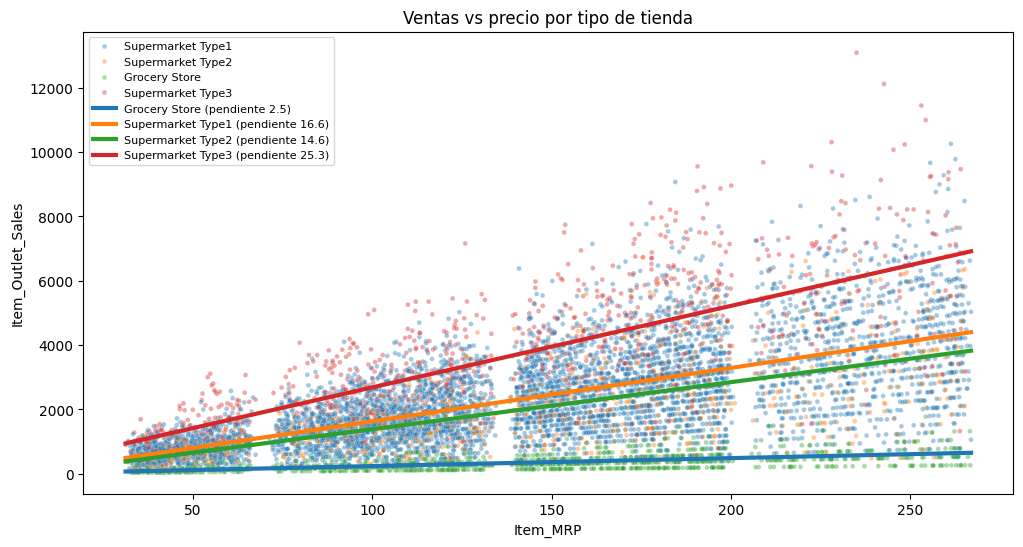

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.scatterplot(x='Item_MRP', y='Item_Outlet_Sales', hue='Outlet_Type', data=sales_df, alpha=0.4, s=12, ax=ax)
xs = np.linspace(sales_df['Item_MRP'].min(), sales_df['Item_MRP'].max(), 50)
for tipo, grupo in sales_df.groupby('Outlet_Type'):
    m, b = np.polyfit(grupo['Item_MRP'], grupo['Item_Outlet_Sales'], 1)
    ax.plot(xs, m * xs + b, lw=3, label=f'{tipo} (pendiente {m:.1f})')
ax.set_title('Ventas vs precio por tipo de tienda')
ax.legend(fontsize=8)
plt.show()

**INGENIERÍA DE CARACTERÍSTICAS**

Una regresión lineal normal sólo aprende una pendiente para Item_MRP, común a todas las tiendas. Para que pueda aprender una pendiente diferente en cada una, se crean interacciones precio × tienda donde una columna por tienda vale el precio del producto cuando el registro pertenece a esa tienda y 0 en otro caso. El modelo sigue siendo lineal, pero ahora puede representar que cada tienda vende distinta cantidad de unidades.

In [ ]:
tiendas = sorted(sales_df['Outlet_Identifier'].unique())
for t in tiendas:
    sales_df[f'MRP_x_{t}'] = sales_df['Item_MRP'] * (sales_df['Outlet_Identifier'] == t)

X = sales_df.drop('Item_Outlet_Sales', axis=1)
y = sales_df['Item_Outlet_Sales']
X.shape

(8523, 20)

**CANALIZACIÓN (PIPELINE)**

Las variables numéricas se imputan con la mediana y se estandarizan; las categóricas se imputan con la moda y se codifican con OneHotEncoder. Después se aplica la regresión lineal.

In [ ]:
def crear_modelo():
    num_pipeline = make_pipeline(SimpleImputer(strategy='median'), StandardScaler())
    cat_pipeline = make_pipeline(SimpleImputer(strategy='most_frequent'),
                                 OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
    preprocessing = ColumnTransformer([
        ('num', num_pipeline, make_column_selector(dtype_include=np.number)),
        ('cat', cat_pipeline, make_column_selector(dtype_exclude=np.number))])
    return make_pipeline(preprocessing, LinearRegression())

**DATOS ATÍPICOS**

En regresión, un dato atípico es un registro que se aleja mucho de lo que el modelo predice para él. Para encontrarlos se ajusta el modelo con todos los datos, se calcula el residuo de cada registro (real − predicho) y se estandariza. Los registros con un residuo estandarizado mayor a 2 en valor absoluto se consideran atípicos porque son productos que en una tienda vendieron muchas más o muchas menos unidades de lo normal, lo que se podría explicar con información que puede no estar en los datos.

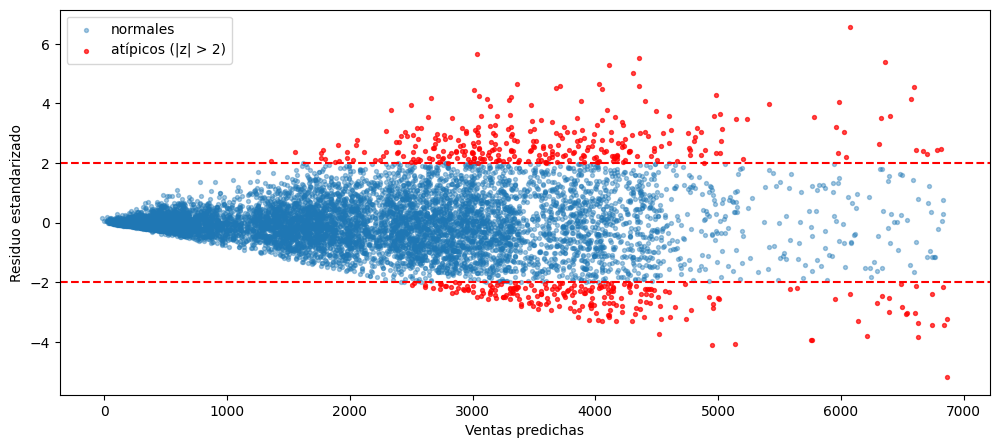

Registros atípicos eliminados: 511 de 8523 (6.0%)


In [ ]:
modelo_diagnostico = crear_modelo().fit(X, y)
predicho = modelo_diagnostico.predict(X)
residuos = y - predicho
z = (residuos - residuos.mean()) / residuos.std()
atipico = z.abs() > 2

plt.figure(figsize=(12, 5))
plt.scatter(predicho[~atipico], z[~atipico], s=8, alpha=0.4, label='normales')
plt.scatter(predicho[atipico], z[atipico], s=8, alpha=0.7, color='red', label='atípicos (|z| > 2)')
plt.axhline(2, color='red', ls='--'); plt.axhline(-2, color='red', ls='--')
plt.xlabel('Ventas predichas'); plt.ylabel('Residuo estandarizado'); plt.legend()
plt.show()

print(f'Registros atípicos eliminados: {atipico.sum()} de {len(X)} ({atipico.mean():.1%})')
X, y = X[~atipico], y[~atipico]

**ENTRENAMIENTO Y EVALUACIÓN DEL MODELO**

Se divide el conjunto en entrenamiento y prueba (80:20) y se entrena el pipeline completo.

In [ ]:
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, train_size=0.8, random_state=1)

lr_model = crear_modelo()
lr_model.fit(Xtrain, ytrain)
predictions = lr_model.predict(Xtest)

print('The Root Mean Square Error (RMSE) is:', round(np.sqrt(mean_squared_error(ytest, predictions)), 2))
print('The R square (R2) is:', round(r2_score(ytest, predictions), 4))

The Root Mean Square Error (RMSE) is: 818.13
The R square (R2) is: 0.7055


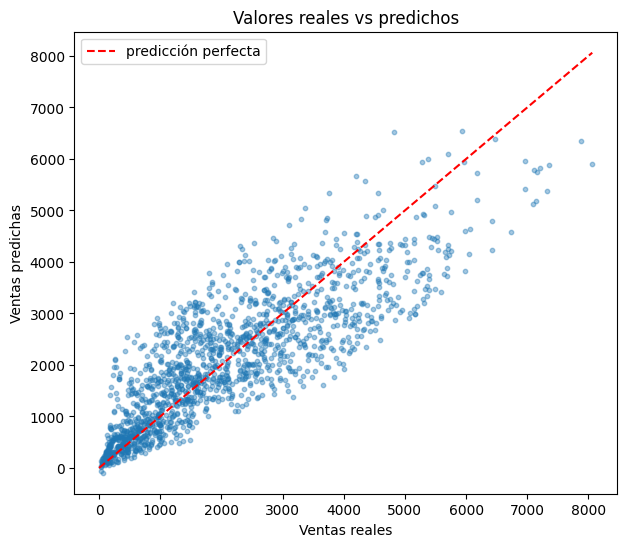

In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(ytest, predictions, s=10, alpha=0.4)
lim = [0, max(ytest.max(), predictions.max())]
plt.plot(lim, lim, 'r--', label='predicción perfecta')
plt.xlabel('Ventas reales'); plt.ylabel('Ventas predichas'); plt.title('Valores reales vs predichos')
plt.legend()
plt.show()

El modelo alcanza un R cuadrada de 0.706, es decir, explica el 70.6% de la variabilidad de las ventas en el conjunto de prueba, con un error promedio (RMSE) de unas 818 unidades. La mejora frente al modelo inicial (R cuadrada = 0.558) se debe a permitir que cada tienda tenga su propia relación entre precio y ventas, y eliminar el 6% de registros con un comportamiento fuera de lo normal.